# 06 — Match visualisation

A one-page picture for any match: the chance of each result, how likely each exact score is, and each team's
recent form. It works for a **past** match (the real score is shown as a star, and the models only use matches
before that date) and for a **future** one.

1. Change the three settings below and run all cells.
2. The picture is saved in `data/predictions/figures/`.

Section 3 draws a chart of the whole next round from the predictions saved by notebook 04.

In [1]:
# ---- Settings ----
HOME_TEAM = "Manchester United"
AWAY_TEAM = "Manchester City"
MATCH_DATE = "2026-01-17"    # a past date shows the real result; a future date is a pure prediction
SAVE_PNG = True

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data import LEAGUE, SEASONS, clean_matches, download_understat_matches
from src.plots import plot_match_prediction, plot_next_round
from src.predict import load_saved_predictions, predict_match_as_of

raw = download_understat_matches(LEAGUE, SEASONS, force_download=False)
matches = clean_matches(raw, verbose=False)
print(f"{len(matches)} played matches loaded, latest {matches['date'].max():%d %b %Y}")

Loading cached raw data: data/raw/understat_ENG-Premier-League_1617-2627.csv
3869 played matches loaded, latest 18 Oct 2026


## 1. One match

The models are trained, and each team's form is measured, using only matches **before** the match date.

Saved data/predictions/figures/Manchester_United_vs_Manchester_City_2026-01-17.png


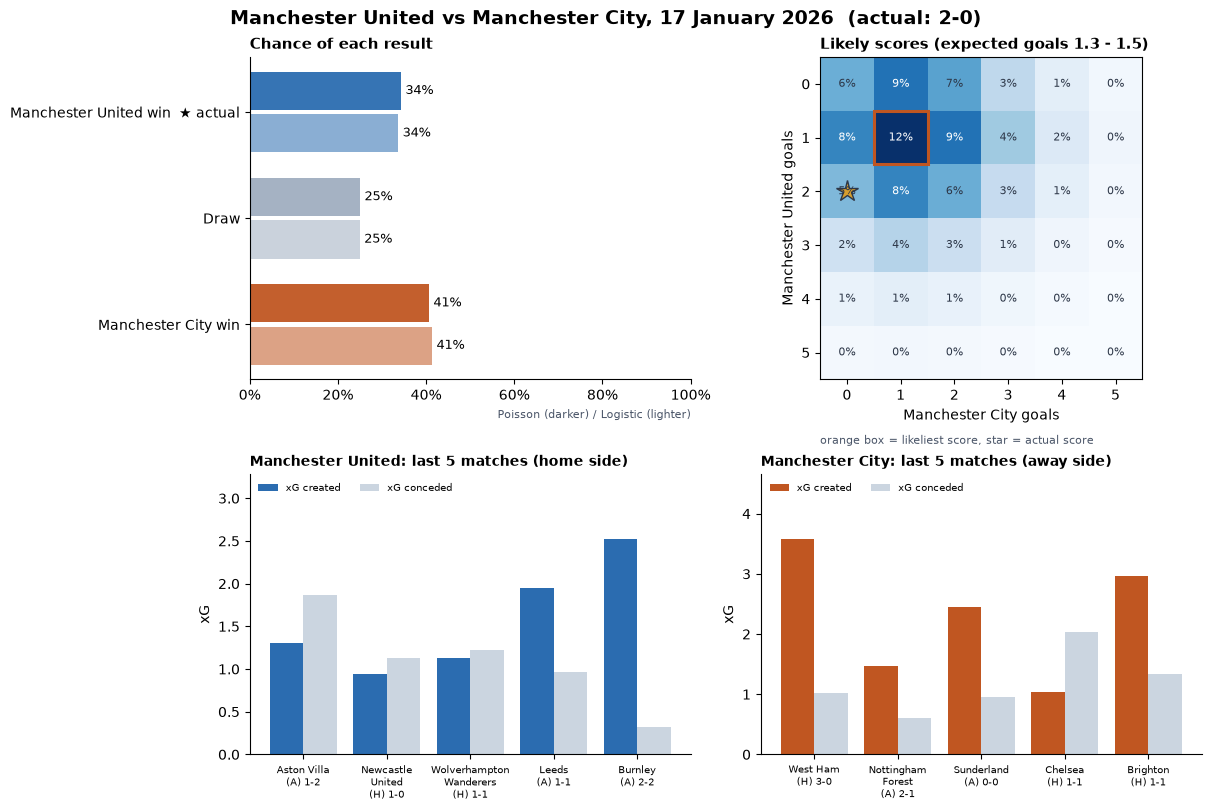

In [3]:
date = pd.Timestamp(MATCH_DATE)
one = predict_match_as_of(matches, HOME_TEAM, AWAY_TEAM, date)

if one["model"].isna().any():
    print(one["note"].iloc[0])
else:
    fig = plot_match_prediction(one, matches, HOME_TEAM, AWAY_TEAM, date)
    if SAVE_PNG:
        out_dir = PROJECT_ROOT / "data" / "predictions" / "figures"
        out_dir.mkdir(parents=True, exist_ok=True)
        path = out_dir / f"{HOME_TEAM}_vs_{AWAY_TEAM}_{date:%Y-%m-%d}.png".replace(" ", "_")
        fig.savefig(path, dpi=150, bbox_inches="tight")
        print(f"Saved {path.relative_to(PROJECT_ROOT)}")
    plt.show()

Saved data/predictions/figures/Chelsea_vs_Tottenham_2026-10-24.png


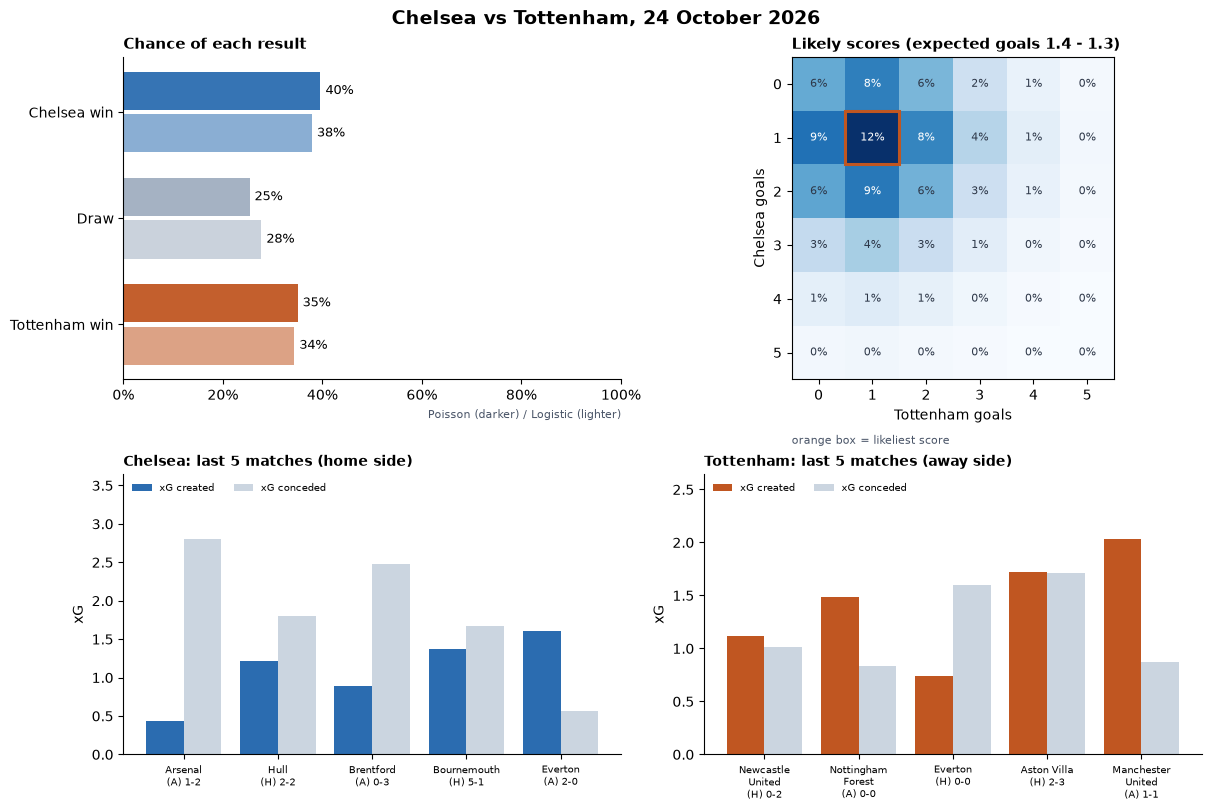

In [6]:
date = pd.Timestamp("2026-10-24")
one = predict_match_as_of(matches, "Chelsea", "Tottenham", date)

if one["model"].isna().any():
    print(one["note"].iloc[0])
else:
    fig = plot_match_prediction(one, matches, "Chelsea", "Tottenham", date)
    if SAVE_PNG:
        out_dir = PROJECT_ROOT / "data" / "predictions" / "figures"
        out_dir.mkdir(parents=True, exist_ok=True)
        path = out_dir / f"Chelsea_vs_Tottenham_{date:%Y-%m-%d}.png"
        fig.savefig(path, dpi=150, bbox_inches="tight")
        print(f"Saved {path.relative_to(PROJECT_ROOT)}")
    plt.show()

**How to read it**

- **Top left:** the chance of a home win, draw and away win, from both models (they are usually close).
- **Top right:** every exact score from the Poisson model. The darker the square, the more likely.
  The orange box is the likeliest score, usually only about 10–15%.
- **Bottom:** each team's last 5 matches. Coloured bar = xG it created, grey = xG it conceded, and the
  label shows the opponent, (H)ome or (A)way, and the real score. This is the form the models see.

## 2. Reading the picture

If the star (actual score) lands on a dark square, the model saw the match coming. A star on a pale square means
a surprise. One match proves little: football is random, and notebook 03 scores the models over thousands of matches.

## 3. The whole next round

Uses the saved predictions of notebook 04, so run that first.

In [5]:
saved = load_saved_predictions()
now = pd.Timestamp.now(tz="UTC").tz_localize(None)
upcoming = saved[(pd.to_datetime(saved["date"]) > now) & (saved["model"] == "Poisson")]
upcoming = (upcoming.sort_values("made_on")
            .drop_duplicates(["date", "home_team", "away_team"], keep="last"))
if upcoming.empty:
    print("No saved predictions for future matches. Run notebook 04 for the next round first.")
else:
    plot_next_round(upcoming)
    plt.show()

No saved predictions for future matches. Run notebook 04 for the next round first.
